# Séance 0 : prise en main

Ce notebook reprend tout ce qu'on a fait en classe. Pour le relancer : **Restart**, puis **Run All**.

1. Une cellule de code s'exécute avec **Shift + Entrée**.
2. La valeur de la dernière ligne d'une cellule s'affiche toute seule, sans `print`.
3. Le numéro entre crochets à gauche donne l'ordre réel d'exécution.

## 1. Rappels du cours précédent

Les outils de base restent les mêmes : listes, dictionnaires, boucles, fonctions.

In [1]:
prix_riz = [488, 512, 530, 547]
prix_riz.append(560)
len(prix_riz), prix_riz[-1]

(5, 560)

In [2]:
prix_moyens = {"riz importé": 520, "huile végétale": 1450}
prix_moyens.get("sucre", 0)

0

In [3]:
def moyenne(valeurs):
    """Renvoie la moyenne d'une liste de nombres."""
    return sum(valeurs) / len(valeurs)


moyenne(prix_riz)

527.4

## 2. Lire le fichier à l'ancienne

Question : quel est le prix moyen du riz importé sur les deux ans, tous marchés confondus ?

Avec ce qu'on sait déjà (`open`, `split`, une boucle), c'est possible, mais long.

In [4]:
total = 0
nombre = 0
with open("donnees/prix_marches.csv", encoding="utf-8") as fichier:
    fichier.readline()
    for ligne in fichier:
        champs = ligne.strip().split(",")
        if champs[3] == "Riz importé":
            total = total + float(champs[5])
            nombre = nombre + 1

round(total / nombre, 1), nombre

(704.9, 288)

## 3. La même question avec pandas

Trois lignes, et le tableau entier devient un objet qu'on peut interroger.

In [5]:
import pandas as pd

prix = pd.read_csv("donnees/prix_marches.csv")
prix.head()

,mois,departement,marche,produit,unite,prix_htg
0,2024-01,Ouest,Croix-des-Bossales,Riz importé,marmite,488.0
1,2024-01,Ouest,Croix-des-Bossales,Riz local,marmite,623.0
2,2024-01,Ouest,Croix-des-Bossales,Maïs moulu,marmite,297.0
3,2024-01,Ouest,Croix-des-Bossales,Farine de blé,marmite,415.0
4,2024-01,Ouest,Croix-des-Bossales,Haricot noir,marmite,750.0


In [6]:
prix.shape

(2304, 6)

In [7]:
riz = prix[prix["produit"] == "Riz importé"]
round(float(riz["prix_htg"].mean()), 1), len(riz)

(704.9, 288)

Même résultat, sans boucle ni conversion à la main. Les séances 1 à 4 expliquent chacune de ces lignes.

## 4. Un aperçu de la suite

Une ligne pour le prix moyen de chaque produit (séance 4), une ligne pour un graphique (séance 6).

In [8]:
prix.groupby("produit")["prix_htg"].mean().round(1).sort_values()

produit
Spaghetti          101.3
Maïs moulu         444.4
Farine de blé      553.1
Sucre              621.3
Riz importé        704.9
Riz local          860.6
Haricot noir      1020.4
Huile végétale    1960.5
Name: prix_htg, dtype: float64

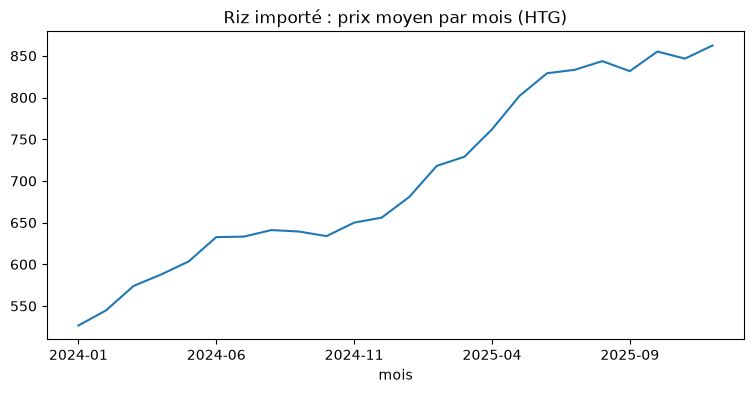

In [9]:
%matplotlib inline
riz_mensuel = riz.groupby("mois")["prix_htg"].mean()
riz_mensuel.plot(title="Riz importé : prix moyen par mois (HTG)", figsize=(9, 4));

## Aller plus loin

À chercher vous-mêmes, pas vu en cours :

- À quoi sert le fichier `uv.lock` ? Que se passe-t-il si on le supprime ?
- Les raccourcis clavier de Jupyter : la différence entre le mode commande et le mode édition.
- Comment exporter ce notebook en page HTML ?

## Sources

- Documentation de uv : https://docs.astral.sh/uv/
- VS Code, Jupyter Notebooks : https://code.visualstudio.com/docs/datascience/jupyter-notebooks
- Wes McKinney, *Python for Data Analysis*, 3e édition, chapitre 1 : https://wesmckinney.com/book/